# Week 8 — Evaluation Expansion

* Compute metrics beyond R²: MAPE and MdAPE.
* Summarize insights (e.g., which price bands perform better).
* Deliverable: 06_evaluation.ipynb + metrics_summary.csv.

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.metrics import r2_score
from IPython.display import display, Markdown

In [10]:
run_dir = Path("/Users/jingying/Documents/IDX Exchange/py/cleaned_data/run_20261014_180636_999980")
model_name = "Tuned XGBoost"

evaluation = pd.read_csv(run_dir / "week7_test_predictions.csv", index_col="row_id")
y_train = pd.read_csv(run_dir / "y_train.csv", index_col="row_id")["ClosePrice"]
range_ids = pd.read_csv(run_dir / "y_test_avm_range.csv", usecols=["row_id"])["row_id"]
test_month = str(evaluation["Test month"].iloc[0])

# Match the original test subset by row ID rather than row position.
evaluation["Within training price bounds"] = evaluation.index.isin(range_ids)

print("Model:", model_name)
print("Test month:", test_month)
print(f"Full test month: {len(evaluation):,} sales")
print(f"Within training price bounds: {evaluation['Within training price bounds'].sum():,} sales")
display(evaluation.head())

Model: Tuned XGBoost
Test month: 2026-04
Full test month: 12,458 sales
Within training price bounds: 12,321 sales


,Test month,Actual,Predicted,Within training price bounds
row_id,,,,
591446,2026-04,1750000.0,1749175.50,True
591448,2026-04,600000.0,718134.06,True
591450,2026-04,3625000.0,3692933.00,True
591451,2026-04,1450000.0,1207359.50,True
591452,2026-04,1500000.0,1454842.60,True


In [12]:
# Positive signed errors mean that the predicted price exceeds the sale price.
evaluation["Error ($)"] = evaluation["Predicted"] - evaluation["Actual"]
evaluation["Absolute error ($)"] = evaluation["Error ($)"].abs()
evaluation["APE (%)"] = 100 * evaluation["Absolute error ($)"] / evaluation["Actual"]
evaluation["Signed error (%)"] = 100 * evaluation["Error ($)"] / evaluation["Actual"]

display(evaluation[["Actual", "Predicted", "Absolute error ($)", "APE (%)"]].head().round(2))

,Actual,Predicted,Absolute error ($),APE (%)
row_id,,,,
591446,1750000.0,1749175.50,824.50,0.05
591448,600000.0,718134.06,118134.06,19.69
591450,3625000.0,3692933.00,67933.00,1.87
591451,1450000.0,1207359.50,242640.50,16.73
591452,1500000.0,1454842.60,45157.40,3.01


In [14]:
# Learn the reporting boundaries from training prices only.
q25, q75, q95 = y_train.quantile([0.25, 0.75, 0.95])
band_names = ["Low", "Medium", "High", "Extreme"]
band_edges = [0, q25, q75, q95, np.inf]

# Assign each test property using its actual sale price.
evaluation["Price band"] = pd.cut(
    evaluation["Actual"], bins=band_edges, labels=band_names,
    right=True, include_lowest=True,
)

band_definitions = pd.DataFrame({
    "Price band": band_names,
    "Price range ($)": [
        f"0 < price <= {q25:,.2f}",
        f"{q25:,.2f} < price <= {q75:,.2f}",
        f"{q75:,.2f} < price <= {q95:,.2f}",
        f"price > {q95:,.2f}",
    ],
})
display(band_definitions)


,Price band,Price range ($)
0,Low,"0 < price <= 630,000.00"
1,Medium,"630,000.00 < price <= 1,426,813.00"
2,High,"1,426,813.00 < price <= 3,050,000.00"
3,Extreme,"price > 3,050,000.00"


In [16]:
def calculate_metrics(sales):
    """Summarize errors on the original dollar scale."""
    return {
        "N": len(sales),
        "R2": r2_score(sales["Actual"], sales["Predicted"]),
        "MAE ($)": sales["Absolute error ($)"].mean(),
        "MAPE (%)": sales["APE (%)"].mean(),
        "MdAPE (%)": sales["APE (%)"].median(),
        "Mean signed error (%)": sales["Signed error (%)"].mean(),
    }

primary_sample = "Within training price bounds"
samples = {
    primary_sample: evaluation.loc[evaluation["Within training price bounds"]].copy(),
    "Full test month": evaluation,
}

records = []
for sample_name, sales in samples.items():
    common = {"Model": model_name, "Test month": test_month, "Test sample": sample_name}
    records.append({**common, "Price band": "Overall", **calculate_metrics(sales)})

    # Use the same predictions and band boundaries for both test samples.
    for band, band_sales in sales.groupby("Price band", observed=True, sort=True):
        records.append({**common, "Price band": str(band), **calculate_metrics(band_sales)})

metrics_summary = pd.DataFrame(records)

# Include the exact band boundaries in the exported summary.
lower_bounds = dict(zip(band_names, band_edges[:-1]))
upper_bounds = dict(zip(band_names, band_edges[1:]))
metrics_summary["Band lower ($)"] = metrics_summary["Price band"].map(lower_bounds)
metrics_summary["Band upper ($)"] = metrics_summary["Price band"].map(upper_bounds)

overall_metrics = metrics_summary.loc[metrics_summary["Price band"].eq("Overall")]
band_metrics = metrics_summary.loc[
    metrics_summary["Test sample"].eq(primary_sample)
    & metrics_summary["Price band"].ne("Overall")
].set_index("Price band")

metric_columns = ["N", "R2", "MAE ($)", "MAPE (%)", "MdAPE (%)", "Mean signed error (%)"]
print("Overall performance")
display(overall_metrics[["Test sample", *metric_columns]].round(4))
print("Price-band performance — within training price bounds")
display(band_metrics[metric_columns].round(4))

Overall performance


,Test sample,N,R2,MAE ($),MAPE (%),MdAPE (%),Mean signed error (%)
0,Within training price bounds,12321,0.8970,160774.5647,12.2989,8.3639,2.0652
5,Full test month,12458,0.0094,387331.9953,13.1265,8.4608,2.3313


Price-band performance — within training price bounds


,N,R2,MAE ($),MAPE (%),MdAPE (%),Mean signed error (%)
Price band,,,,,,
Low,3067,0.0818,59366.3512,13.7324,7.8716,7.4281
Medium,6000,0.3819,104359.4250,10.7674,7.5583,1.8360
High,2566,0.2617,261662.3399,13.0992,9.7509,-1.2795
Extreme,688,0.2857,728553.3406,16.2789,12.5856,-7.3684


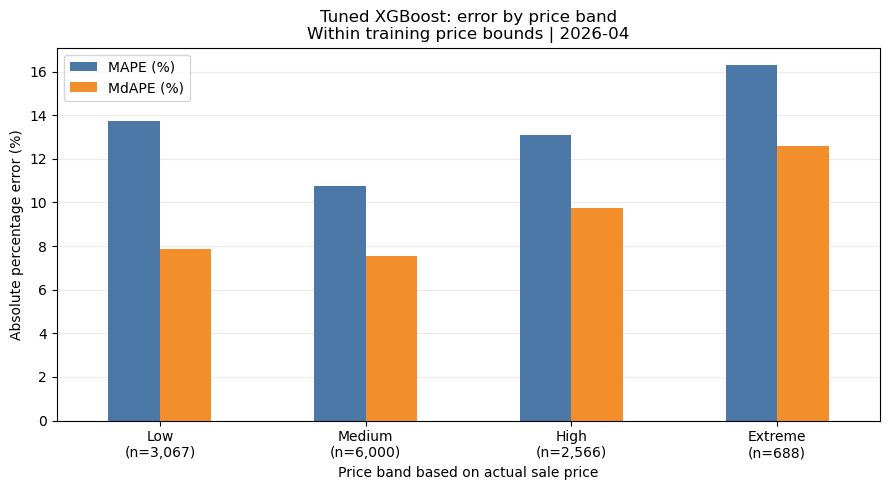

In [18]:
# Show sample counts with each band to put its error metrics in context.
ax = band_metrics[["MAPE (%)", "MdAPE (%)"]].plot.bar(
    figsize=(9, 5), color=["#4C78A8", "#F28E2B"], rot=0,
)
labels = [f"{band}\n(n={int(row['N']):,})" for band, row in band_metrics.iterrows()]
ax.set_xticklabels(labels)
ax.set_xlabel("Price band based on actual sale price")
ax.set_ylabel("Absolute percentage error (%)")
ax.set_title(f"{model_name}: error by price band\nWithin training price bounds | {test_month}")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


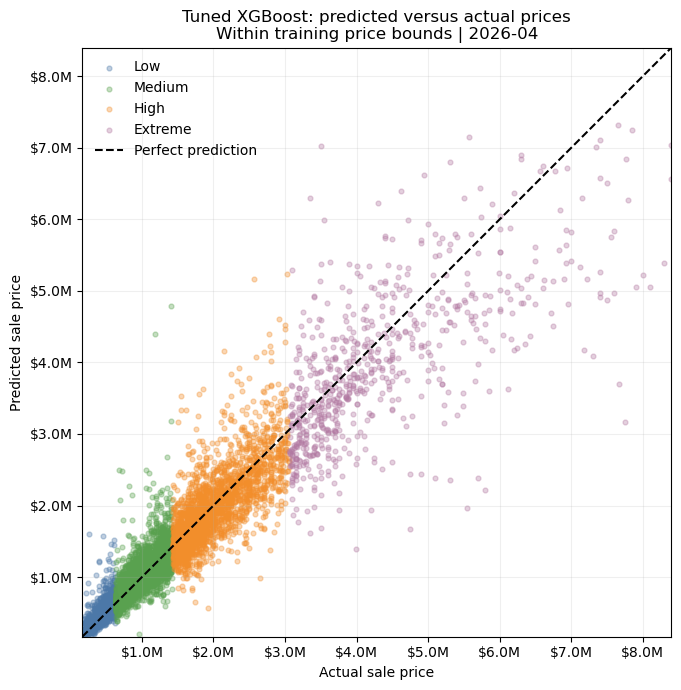

In [24]:
sales = samples[primary_sample]
fig, ax = plt.subplots(figsize=(7, 7))

# Colors follow the same ordered price bands as the error chart.
colors = ["#4C78A8", "#59A14F", "#F28E2B", "#B279A2"]
for band, color in zip(band_names, colors):
    band_sales = sales.loc[sales["Price band"].eq(band)]
    ax.scatter(
        band_sales["Actual"], band_sales["Predicted"],
        s=12, alpha=0.35, color=color, label=band,
    )

# A point on this line is a perfect prediction.
lower = min(sales["Actual"].min(), sales["Predicted"].min())
upper = max(sales["Actual"].max(), sales["Predicted"].max())
ax.plot([lower, upper], [lower, upper], "k--", linewidth=1.5, label="Perfect prediction")
ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_aspect("equal", adjustable="box")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: f"${value / 1e6:.1f}M"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"${value / 1e6:.1f}M"))
ax.set_xlabel("Actual sale price")
ax.set_ylabel("Predicted sale price")
ax.set_title(f"{model_name}: predicted versus actual prices\nWithin training price bounds | {test_month}")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [30]:
# Identify the strongest and weakest bands using median percentage error.
best_band = band_metrics["MdAPE (%)"].idxmin()
worst_band = band_metrics["MdAPE (%)"].idxmax()
largest_dollar_error_band = band_metrics["MAE ($)"].idxmax()

# Compare the same fitted model on the two test samples.
overall_by_sample = overall_metrics.set_index("Test sample")
primary = overall_by_sample.loc[primary_sample]
full = overall_by_sample.loc["Full test month"]
excluded_count = int(full["N"] - primary["N"])

print("Overall performance — within training price bounds")
print(f"R²: {primary['R2']:.4f} | MAE: ${primary['MAE ($)']:,.0f} | "
      f"MAPE: {primary['MAPE (%)']:.2f}% | MdAPE: {primary['MdAPE (%)']:.2f}%")

print(f"\nLowest MdAPE: {best_band} — {band_metrics.loc[best_band, 'MdAPE (%)']:.2f}% "
      f"({int(band_metrics.loc[best_band, 'N']):,} sales)")
print(f"Highest MdAPE: {worst_band} — {band_metrics.loc[worst_band, 'MdAPE (%)']:.2f}% "
      f"({int(band_metrics.loc[worst_band, 'N']):,} sales)")
print(f"Largest MAE: {largest_dollar_error_band} — "
      f"${band_metrics.loc[largest_dollar_error_band, 'MAE ($)']:,.0f}")
print(f"Mean signed percentage error: {primary['Mean signed error (%)']:+.2f}%")

print(f"\nFull test month — includes {excluded_count:,} sales outside training price bounds")
print(f"R²: {full['R2']:.4f} | MAE: ${full['MAE ($)']:,.0f} | "
      f"MAPE: {full['MAPE (%)']:.2f}% | MdAPE: {full['MdAPE (%)']:.2f}%")

Overall performance — within training price bounds
R²: 0.8970 | MAE: $160,775 | MAPE: 12.30% | MdAPE: 8.36%

Lowest MdAPE: Medium — 7.56% (6,000 sales)
Highest MdAPE: Extreme — 12.59% (688 sales)
Largest MAE: Extreme — $728,553
Mean signed percentage error: +2.07%

Full test month — includes 137 sales outside training price bounds
R²: 0.0094 | MAE: $387,332 | MAPE: 13.13% | MdAPE: 8.46%


In [32]:
output_file = run_dir / "metrics_summary.csv"
metrics_summary.to_csv(output_file, index=False)

print("Saved:", output_file)
display(metrics_summary.round(4))


Saved: /Users/jingying/Documents/IDX Exchange/py/cleaned_data/run_20261014_180636_999980/metrics_summary.csv


,Model,Test month,Test sample,Price band,N,R2,MAE ($),MAPE (%),MdAPE (%),Mean signed error (%),Band lower ($),Band upper ($)
0,Tuned XGBoost,2026-04,Within training price bounds,Overall,12321,0.8970,1.607746e+05,12.2989,8.3639,2.0652,NaN,NaN
1,Tuned XGBoost,2026-04,Within training price bounds,Low,3067,0.0818,5.936635e+04,13.7324,7.8716,7.4281,0.0,630000.0
2,Tuned XGBoost,2026-04,Within training price bounds,Medium,6000,0.3819,1.043594e+05,10.7674,7.5583,1.8360,630000.0,1426813.0
3,Tuned XGBoost,2026-04,Within training price bounds,High,2566,0.2617,2.616623e+05,13.0992,9.7509,-1.2795,1426813.0,3050000.0
4,Tuned XGBoost,2026-04,Within training price bounds,Extreme,688,0.2857,7.285533e+05,16.2789,12.5856,-7.3684,3050000.0,inf
5,Tuned XGBoost,2026-04,Full test month,Overall,12458,0.0094,3.873320e+05,13.1265,8.4608,2.3313,NaN,NaN
6,Tuned XGBoost,2026-04,Full test month,Low,3123,0.1427,6.126325e+04,15.9929,8.0911,9.7814,0.0,630000.0
7,Tuned XGBoost,2026-04,Full test month,Medium,6000,0.3819,1.043594e+05,10.7674,7.5583,1.8360,630000.0,1426813.0
8,Tuned XGBoost,2026-04,Full test month,High,2566,0.2617,2.616623e+05,13.0992,9.7509,-1.2795,1426813.0,3050000.0
9,Tuned XGBoost,2026-04,Full test month,Extreme,769,-0.0152,4.338719e+06,19.9837,15.0325,-12.0118,3050000.0,inf
